In [1]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
proposal_number = 101927227  # noqa
run = 100  # noqa

In [3]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='epix_6/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)

In [4]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

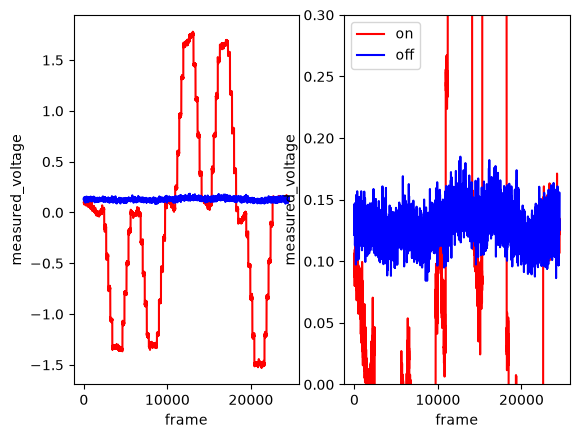

In [5]:
on_meta = metadata[metadata['laser_on']]
off_meta = metadata[~metadata['laser_on']]
fig, axs = plt.subplots(1, 2)
for ax in axs:
    ax.plot(on_meta['measured_voltage'], label='on', color='red')
    ax.plot(off_meta['measured_voltage'], label='off', color='blue')
    ax.set_xlabel('frame')
    ax.set_ylabel('measured_voltage')
axs[1].set_ylim(bottom=0.0, top=0.3)
plt.legend()
plt.show()

In [6]:
rois = [
    (slice(160, 170), slice(168, 178)) # whole ROI
]

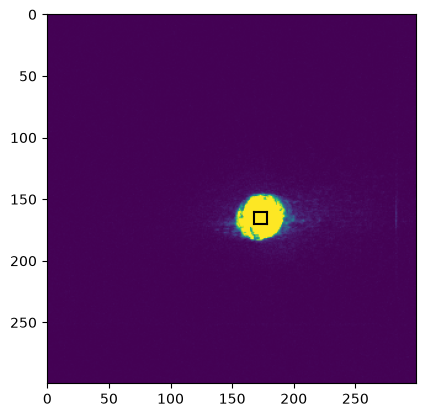

In [7]:
xcs.plot_detector_image(h5, h5dict, samplerate=100)
roi_colors = ['black', 'red', 'green', 'blue', 'purple', 'brown']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

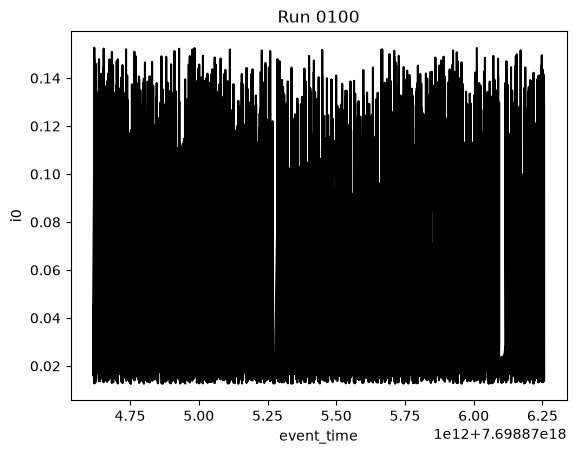

In [8]:
xcs.plot_i0_vs_time(metadata, valid).show()

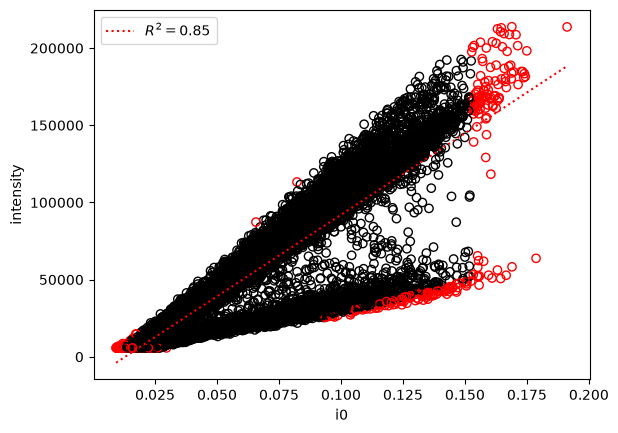

In [9]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

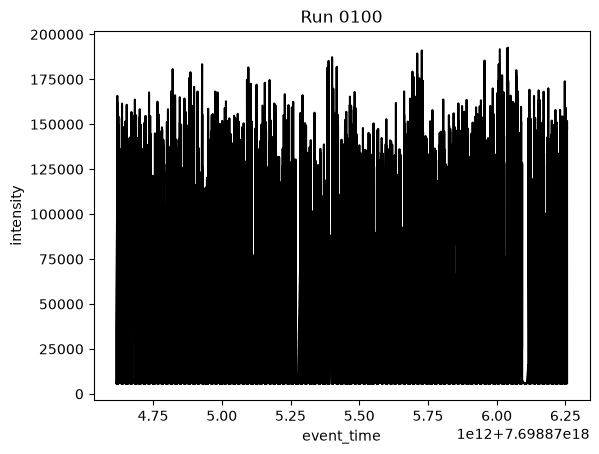

In [10]:
xcs.plot_intensity_vs_time(metadata, valid).show()

In [11]:
delays = h5[h5dict.delay][...]
diff = np.diff(delays)
u_diffs, counts = np.unique(diff, return_counts=True)
typical_dt = u_diffs[u_diffs > 0][np.argmax(counts[u_diffs > 0])]
print(f'{typical_dt=:0.2f}')

typical_dt=117.65


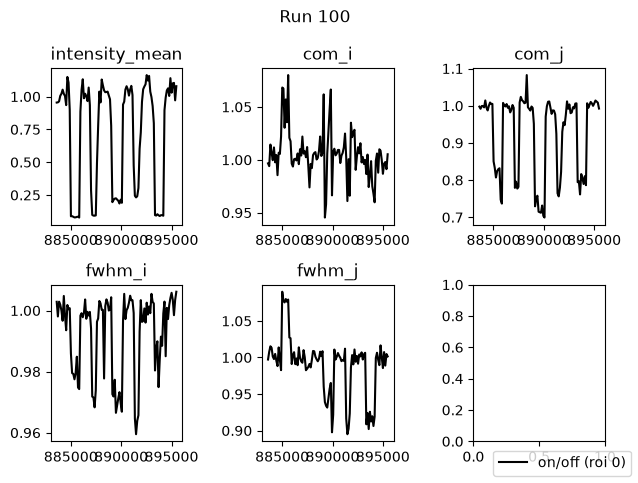

In [12]:

fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'on/off (roi {j})' if i == 0 else None
        ax.plot(trxrd.index, trxrd[f'on_{tag}']/trxrd[f'off_{tag}'], color=color, linestyle='-', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

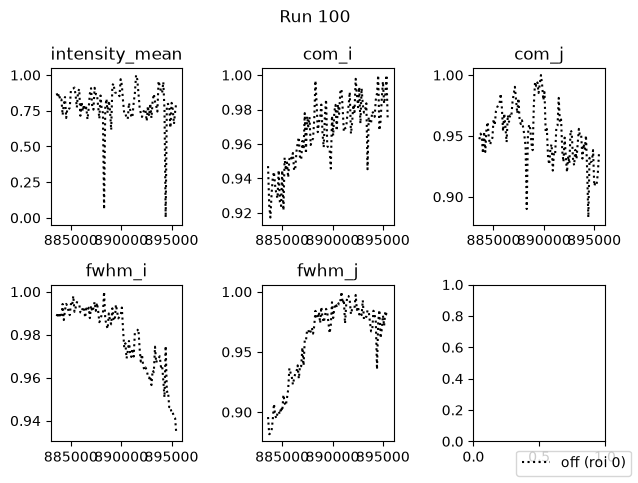

In [13]:


def normalize(a):
    return a / np.amax(a)


fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'off (roi {j})' if j == i else None
        ax.plot(trxrd.index, normalize(trxrd[f'off_{tag}']), color=color, linestyle=':', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

/sdf/data/lcls/ds/xcs/xcs101927227/results/bfichera/xcs-code-stockpile/src/xcs_code_stockpile/static_correlation.py:32: RuntimeWarning: invalid value encountered in divide
  ret = numerator / denominator - offset


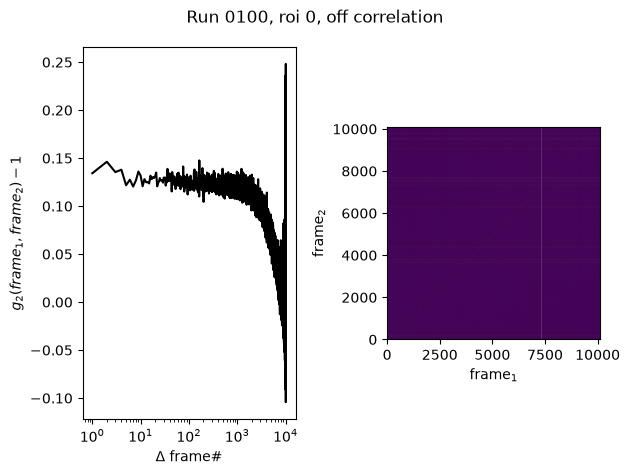

In [14]:

off_filter = valid[~metadata['laser_on']]
off_metadata = metadata[~metadata['laser_on']]
for j, (roi, color) in enumerate(zip(rois, roi_colors)):
    off_st_corr, off_st_twotime = xcs.calc_static_correlation(h5, h5dict, off_metadata, off_filter, roi=roi, denominator_type='nanmean', ret_twotime=True)
    fig, axs = plt.subplots(1, 2)
    axs[0].semilogx(off_st_corr, label=f'roi {j}', color=color)
    axs[1].imshow(off_st_twotime, origin='lower')
    axs[0].set_xlabel(r'$\Delta$ frame#')
    axs[0].set_ylabel(r'$g_2(frame_1, frame_2) - 1$')
    axs[1].set_xlabel(r'frame$_1$')
    axs[1].set_ylabel(r'frame$_2$')
    fig.suptitle(f'Run {run:04d}, roi {j}, off correlation')
    fig.tight_layout()
    fig.show()

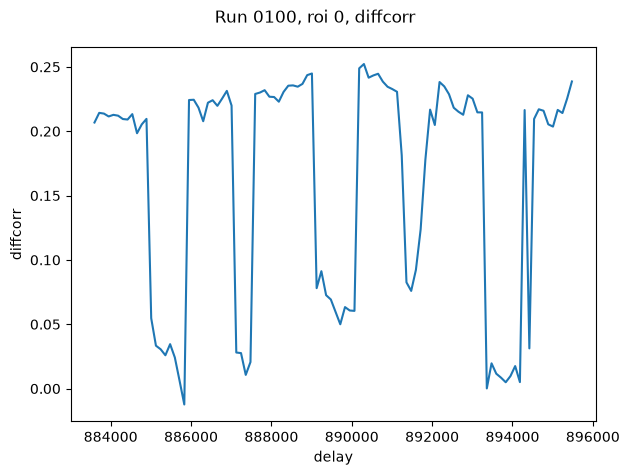

In [15]:
# TODO
# Try other reversibility conditions?
comparable_labtime_frames = 500
per_frame_time = (metadata['event_time'].max() - metadata['event_time'].min())/len(metadata)
labtime_bin_interval = comparable_labtime_frames * per_frame_time
for j, (roi, color) in enumerate(zip(rois, roi_colors)):
    diffcorr = xcs.differential_correlation('strong',
                                            h5,
                                            h5dict,
                                            metadata,
                                            valid,
                                            typical_dt,
                                            labtime_bin_interval,
                                            roi=roi,
                                            denominator_type='nanmean')
    fig, ax = plt.subplots()
    ax.plot(diffcorr.index, diffcorr)
    ax.set_xlabel('delay')
    ax.set_ylabel('diffcorr')
    fig.suptitle(f'Run {run:04d}, roi {j}, diffcorr')
    fig.tight_layout()
    fig.show()